# K-Means clustering: are there groups of adolescents with similar sleep and screen profiles?

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

This notebook applies the Week 9 unsupervised-learning material (`01_week9_KMeansClustering.ipynb`) to the project data. The other model notebooks are **supervised**: they are given the `depressed` label and learn to predict it. K-Means is **unsupervised**: it is given no label and looks for groups of similar adolescents.

As in the Week 9 example, two features are used so the result can be plotted: **average sleep hours** and **estimated leisure screen hours**. The BDI-II score is not given to the algorithm. It is only looked at afterwards, to describe the clusters.

There is no train/test split in this notebook, as in the Week 9 notebook: nothing is being predicted, so all 4,810 adolescents are clustered.

**Learning goals (from Week 9), applied here**
- Explain why feature scaling matters for a distance-based method.
- Run K-Means and describe the clusters it returns.
- Use the elbow method and the silhouette score as guides for choosing K.
- Check whether the clusters depend on the features chosen.
- Recognise the limitations of K-Means.

---
## Step 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Fixing the random seed makes the starting centroids reproducible
RANDOM_STATE = 42

---
## Step 2. Load the data and look at the two features

Before clustering, the scatter plot is checked for visible groups.

Number of adolescents: 4810
Correlation between the two features: -0.227


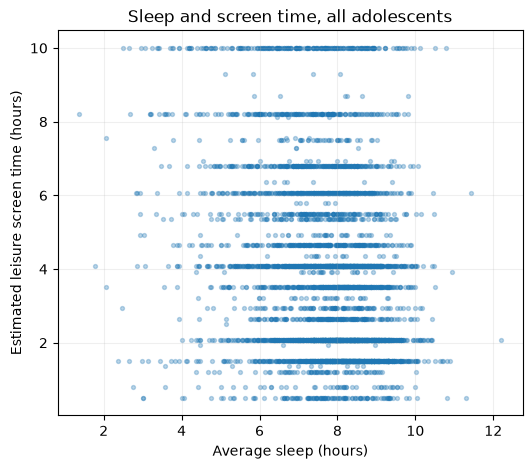

In [2]:
df = pd.read_csv("../data/processed/model_ready.csv")

features = ["avg_sleep_hours", "est_leisure_screen_hours"]

print(f"Number of adolescents: {len(df)}")
print(f"Correlation between the two features: {df[features].corr().iloc[0, 1]:.3f}")

plt.figure(figsize=(6, 5))
plt.scatter(df["avg_sleep_hours"], df["est_leisure_screen_hours"], s=8, alpha=0.3)
plt.xlabel("Average sleep (hours)")
plt.ylabel("Estimated leisure screen time (hours)")
plt.title("Sleep and screen time, all adolescents")
plt.grid(alpha=0.2)
plt.show()

## **Explanation**

- There are 4,810 adolescents.
- **No separate groups are visible.** The points form one continuous cloud, densest at around 7 to 9 hours of sleep and 2 to 4 hours of screen time.
- Sleep and screen time are weakly negatively correlated (r = −0.23): adolescents with more screen time tend to sleep slightly less.
- **Screen time falls on horizontal bands** because it is an estimate derived from survey answer categories, not a direct measurement. Distances along this axis are therefore coarser than they look.
- A visual impression is not proof either way, but nothing here suggests natural groups.

---
## Step 3. Distance and feature scaling

K-Means uses **Euclidean distance**, so a feature with a larger spread would count for more. Both features are measured in hours, but their spreads differ. Standardisation (subtract the mean, divide by the standard deviation) puts them on a comparable scale.

The scaler is fitted on all the data here. There is no test set to leak into, because no model is being evaluated on held-out data.

In [3]:
print("Original feature ranges:")
display(df[features].agg(["min", "max", "mean", "std"]).round(2))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print("Standardised feature ranges:")
display(pd.DataFrame(X_scaled, columns=features).agg(["min", "max", "mean", "std"]).round(2))

Original feature ranges:


,avg_sleep_hours,est_leisure_screen_hours
min,1.36,0.50
max,12.21,10.00
mean,7.69,3.96
std,1.27,2.39


Standardised feature ranges:


,avg_sleep_hours,est_leisure_screen_hours
min,-4.98,-1.45
max,3.56,2.53
mean,-0.00,0.00
std,1.00,1.00


## **Explanation**

- Both features are in hours, but screen time is almost twice as spread out (SD 2.39 against 1.27). Without scaling, screen time would count for more in every distance.
- After standardisation both have mean 0 and SD 1, so they contribute equally.
- The standardised minimum for sleep is −4.98: a few adolescents report very short sleep (1.36 hours at the lowest). Extreme values like this pull centroids towards them, because a centroid is a mean.

---
## Step 4. Run K-Means with K = 3

K-Means repeats two steps until nothing changes:
1. **Assign** each adolescent to the nearest centroid.
2. **Move** each centroid to the mean of the adolescents assigned to it.

The settings are the ones used in the Week 9 notebook: `n_clusters = 3`, `init = "k-means++"` (starting centroids placed far apart) and `n_init = 20` (the algorithm is run from 20 different starts and the best result is kept).

The cluster numbers K-Means returns are arbitrary. They are renumbered here from longest to shortest average sleep, so the numbering is the same every time the notebook is run.

Inertia: 4040.3
Number of adolescents in each cluster:
cluster
0    2882
1    1057
2     871


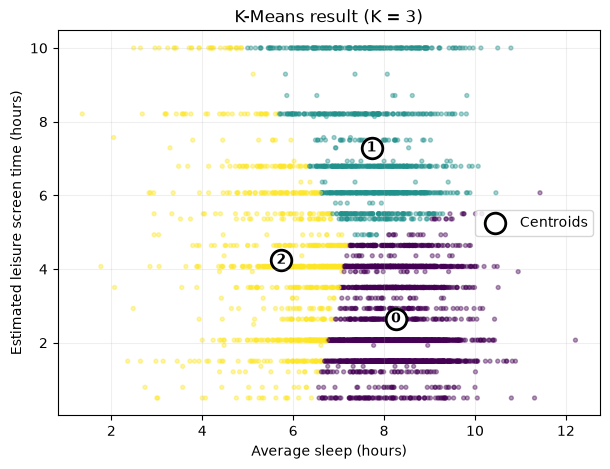

In [4]:
def run_kmeans(X, k):
    return KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=RANDOM_STATE).fit(X)

def ordered_labels(labels, sleep_hours):
    # Renumber clusters so that cluster 0 has the longest mean sleep, cluster 1 the next, and so on
    order = pd.Series(sleep_hours.values).groupby(labels).mean().sort_values(ascending=False).index
    return pd.Series(labels).map({old: new for new, old in enumerate(order)}).to_numpy()

kmeans = run_kmeans(X_scaled, 3)

clustered = df.copy()
clustered["cluster"] = ordered_labels(kmeans.labels_, df["avg_sleep_hours"])

# Centroids in the original units (hours) = the mean of each cluster's adolescents
centroids = clustered.groupby("cluster")[features].mean()

print(f"Inertia: {kmeans.inertia_:.1f}")
print("Number of adolescents in each cluster:")
print(clustered["cluster"].value_counts().sort_index().to_string())

plt.figure(figsize=(7, 5))
plt.scatter(clustered["avg_sleep_hours"], clustered["est_leisure_screen_hours"],
            c=clustered["cluster"], s=8, alpha=0.4)
plt.scatter(centroids["avg_sleep_hours"], centroids["est_leisure_screen_hours"],
            marker="o", s=220, c="white", edgecolor="black", linewidth=2, label="Centroids")
for cluster_id, row in centroids.iterrows():
    plt.annotate(str(cluster_id), (row["avg_sleep_hours"], row["est_leisure_screen_hours"]),
                 ha="center", va="center", fontweight="bold")
plt.xlabel("Average sleep (hours)")
plt.ylabel("Estimated leisure screen time (hours)")
plt.title("K-Means result (K = 3)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## **Explanation**

- K-Means returns three clusters of 2,882, 1,057 and 871 adolescents. They are far from equal in size.
- **Cluster 0** (largest): longer sleep, low screen time. **Cluster 1:** high screen time. **Cluster 2:** short sleep.
- **The borders are straight cuts through a continuous cloud.** There are no gaps between the clusters: adolescents on either side of a border are almost identical, yet they receive different labels.
- The cluster numbers are only labels. Cluster 2 is not "more" of anything than cluster 0.
- Inertia is 4,040.3. On its own this number means little; it is used in Step 6 to compare values of K.

---
## Step 5. Describe the clusters

The first table shows the mean and standard deviation of the two clustering features in each cluster.

The second table brings in variables that K-Means **did not see**: the mean BDI-II total, the share above the clinical threshold, and the share of girls. This shows whether the sleep and screen groups differ on the outcome in the research question.

In [5]:
display(clustered.groupby("cluster")[features].agg(["count", "mean", "std"]).round(2))

outcome_summary = clustered.groupby("cluster").agg(
    adolescents=("depressed", "size"),
    mean_bdi_total=("bdi_total", "mean"),
    share_depressed=("depressed", "mean"),
    share_girls=("sex_binary", "mean"),
).round(3)

print(f"Share depressed across all adolescents: {df['depressed'].mean():.3f}")
outcome_summary

avg_sleep_hours             est_leisure_screen_hours            
                  count  mean   std                    count  mean   std
cluster                                                                 
0                  2882  8.26  0.76                     2882  2.65  1.18
1                  1057  7.73  0.92                     1057  7.29  1.60
2                   871  5.74  1.04                      871  4.24  2.13

Share depressed across all adolescents: 0.164


,adolescents,mean_bdi_total,share_depressed,share_girls
cluster,,,,
0,2882,6.172,0.127,0.486
1,1057,7.728,0.172,0.445
2,871,10.355,0.276,0.567


## **Explanation**

- **Cluster 0 (2,882 adolescents):** mean sleep 8.26 hours, mean screen time 2.65 hours.
- **Cluster 1 (1,057):** mean sleep 7.73 hours, mean screen time 7.29 hours.
- **Cluster 2 (871):** mean sleep 5.74 hours, mean screen time 4.24 hours. Screen time varies most in this cluster (SD 2.13), so it is defined by short sleep and not by screen use.
- **The clusters differ on the outcome, which K-Means never saw.** The share above the BDI-II threshold is 12.7% in cluster 0, 17.2% in cluster 1 and 27.6% in cluster 2, against 16.4% overall. Mean BDI-II totals follow the same order (6.2, 7.7, 10.4).
- The short-sleep cluster has more than twice the rate of the long-sleep, low-screen cluster. This agrees with the supervised models, where the sleep features mattered most.
- **Most adolescents in every cluster are below the threshold**, including 72% of cluster 2. The clusters describe sleep and screen profiles; they do not identify who is depressed.
- Cluster 2 also has the highest share of girls (56.7%), and girls have a higher rate above the threshold in this dataset, so part of the difference between clusters may reflect sex and not sleep alone.
- Labels such as "at risk" are not justified by this analysis: the data are cross-sectional and the clusters were produced by an algorithm, not by a clinical definition.

---
## Step 6. How many clusters? Elbow method and silhouette score

K-Means needs K in advance. Two guides from Week 9:
- **Elbow method:** plot **inertia** (the within-cluster sum of squared distances to the assigned centroid) against K and look for where the improvement levels off. Inertia always decreases as K grows.
- **Silhouette score:** for each adolescent, compares how close they are to their own cluster with how close they are to the nearest other cluster. It ranges from −1 to 1; higher means better-separated clusters.

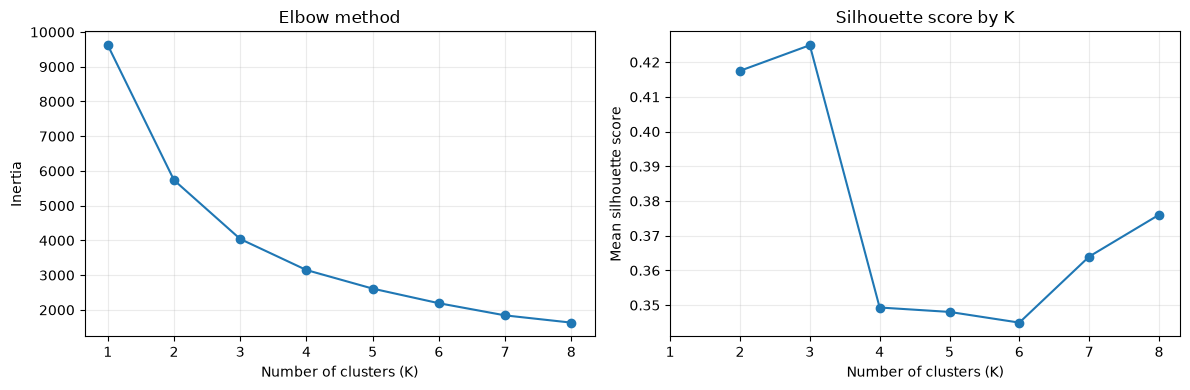

,inertia,mean_silhouette,inertia_drop_%
K,,,
1,9620.000,NaN,NaN
2,5734.963,0.418,40.385
3,4040.326,0.425,29.549
4,3146.790,0.349,22.115
5,2612.305,0.348,16.985
6,2191.655,0.345,16.103
7,1841.616,0.364,15.971
8,1632.969,0.376,11.330


In [6]:
k_values = range(1, 9)
inertias, silhouettes = [], []

for k in k_values:
    candidate = run_kmeans(X_scaled, k)
    inertias.append(candidate.inertia_)
    # The silhouette score needs at least two clusters
    silhouettes.append(silhouette_score(X_scaled, candidate.labels_) if k > 1 else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow method")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set_ylabel("Mean silhouette score")
axes[1].set_title("Silhouette score by K")
for ax in axes:
    ax.set_xticks(list(k_values))
    ax.set_xlabel("Number of clusters (K)")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

k_table = pd.DataFrame({"K": list(k_values), "inertia": inertias, "mean_silhouette": silhouettes}).set_index("K")
k_table["inertia_drop_%"] = (-k_table["inertia"].pct_change() * 100)
k_table.round(3)

## **Explanation**

- **Elbow method:** inertia falls by 40% from K = 1 to 2, by 30% from 2 to 3, by 22% from 3 to 4, and by 11 to 17% for each step after that. The curve bends gradually. There is no sharp elbow; K = 2 or K = 3 could both be argued.
- **Silhouette score:** highest at K = 3 (0.425), with K = 2 almost the same (0.418). It drops to about 0.35 for K = 4 to 6.
- **The two guides roughly agree on K = 2 or 3**, so K = 3 is a reasonable choice, but neither points to it strongly.
- **A silhouette of 0.43 is moderate.** A score near 1 would mean well-separated groups; this value fits clusters that touch each other, as the plot in Step 4 shows.
- These scores are guides for choosing K. They are not evidence that three natural groups of adolescents exist.

---
## Step 7. Do the clusters depend on the features chosen?

A limitation from the lecture: results depend on which features are selected. K-Means is repeated with all six continuous sleep and screen features. `sex_binary` is left out because a 0/1 variable is not suited to Euclidean distance.

With six features the clusters cannot be drawn in one plot, so they are compared through tables.

In [7]:
six_features = [
    "screen_time_index", "est_leisure_screen_hours", "sleep_quality_index",
    "avg_sleep_hours", "midsleep_weekend_hours", "social_jetlag_hours",
]
X6_scaled = StandardScaler().fit_transform(df[six_features])

kmeans6 = run_kmeans(X6_scaled, 3)
clustered["cluster_6_features"] = ordered_labels(kmeans6.labels_, df["avg_sleep_hours"])

print(f"Mean silhouette score, 2 features: {silhouette_score(X_scaled, kmeans.labels_):.3f}")
print(f"Mean silhouette score, 6 features: {silhouette_score(X6_scaled, kmeans6.labels_):.3f}")

print("\nCluster means with six features:")
display(clustered.groupby("cluster_6_features")[six_features].mean().round(2))

display(clustered.groupby("cluster_6_features").agg(
    adolescents=("depressed", "size"),
    mean_bdi_total=("bdi_total", "mean"),
    share_depressed=("depressed", "mean"),
).round(3))

print("Rows: clusters from two features. Columns: clusters from six features.")
pd.crosstab(clustered["cluster"], clustered["cluster_6_features"])

Mean silhouette score, 2 features: 0.425
Mean silhouette score, 6 features: 0.251

Cluster means with six features:


,screen_time_index,est_leisure_screen_hours,sleep_quality_index,avg_sleep_hours,midsleep_weekend_hours,social_jetlag_hours
cluster_6_features,,,,,,
0,2.71,2.80,1.73,8.29,4.57,1.71
1,4.63,7.31,2.03,7.14,6.24,2.74
2,2.88,3.03,2.11,7.06,6.84,3.39


,adolescents,mean_bdi_total,share_depressed
cluster_6_features,,,
0,2377,5.860,0.111
1,1171,8.851,0.219
2,1262,8.465,0.212


Rows: clusters from two features. Columns: clusters from six features.


cluster_6_features,0,1,2
cluster,,,
0,2102,34,746
1,132,883,42
2,143,254,474


## **Explanation**

- **The silhouette score falls from 0.425 to 0.251** with six features: the clusters are less well separated.
- **The clusters change meaning.** With six features the three groups are: longer sleep with early sleep timing and low screen time (2,377 adolescents); high screen time, about 7.3 hours (1,171); and low screen time but late weekend sleep timing and the most social jetlag (1,262). There is no longer a "short sleep" cluster: its 871 adolescents are spread across all three new clusters (143, 254 and 474).
- **About 72% of adolescents stay in the matching cluster** (the diagonal of the last table: 2,102 + 883 + 474 of 4,810). More than a quarter change group when the features change.
- **The link with the outcome is still there but looks different:** 11.1% above the threshold in the first cluster, against 21.9% and 21.2% in the other two.
- The grouping depends on which features are chosen. Neither set of clusters is the "true" one.

---
## Summary of findings

- **K-Means is unsupervised:** it grouped adolescents by sleep and screen time without seeing their BDI-II scores.
- **Scaling mattered:** screen time has almost twice the spread of sleep hours and would otherwise have dominated the distances.
- **With K = 3, the clusters are** longer sleep with low screen time (2,882), high screen time (1,057) and short sleep (871).
- **The elbow method and the silhouette score both point loosely to K = 2 or 3.** The best silhouette score is a moderate 0.43.
- **The clusters differ on depression even though it was not used:** 12.7%, 17.2% and 27.6% above the threshold, against 16.4% overall. Short sleep goes with the highest rate, in line with the supervised notebooks.
- **The clusters are probably not natural groups.** The scatter plot shows one continuous cloud, and K-Means has cut it into three pieces. It always returns K clusters, whether or not groups exist.
- **The result depends on the features chosen:** with six features the silhouette score drops to 0.25, the clusters take on different meanings and more than a quarter of adolescents change group.
- **Limits for the research question:** most adolescents in every cluster are below the threshold, sex differs between clusters, and the data are cross-sectional. The clusters describe profiles; they do not predict or explain depression.
- A cluster is a mathematical result, not automatically a scientific discovery.